# Unsupervised Learning: Segment, Detect, Propagate with Scikit-Learn

Unsupervised learning from Hands-On Machine Learning as practitioners use it: choose the number of k-means clusters with inertia and silhouette scores, cluster the moons with DBSCAN, fit Gaussian mixtures and pick the component count with BIC, turn density into an anomaly detector, then label only 50 digits and propagate their labels through the clusters.

### Configuration

In [1]:
%env OMP_NUM_THREADS=6

%load_ext autoreload
%autoreload 2

env: OMP_NUM_THREADS=6


In [2]:
import os
import tempfile

import numpy as np
from clustering_plots import show_clusters
from sklearn.datasets import load_digits, make_moons
from unsupervised_learning import *

### K-Means and Choosing k

Fit k-means on blob data and pick the number of clusters the two ways practitioners do: the inertia elbow and the silhouette score.

In [3]:
# ---- 1. How many clusters? ----
X, y = blobs_data()
inertia = inertia_curve(X, [1, 2, 3, 4, 5, 6, 7, 8])
sil = silhouette_curve(X, [2, 3, 4, 5, 6, 7, 8])
print('inertia by k:      ' + '  '.join(f'{k}:{v:,.0f}' for k, v in inertia.items()))
print('silhouette by k:   ' + '  '.join(f'{k}:{v:.3f}' for k, v in sil.items()))
print(
    f'silhouette picks k = {best_k_by_silhouette(sil)};\nthe data was generated with 5 blobs '
    f'(three of them tightly packed, which is why 4 looks good too)'
)

inertia by k:      1:3,536  2:1,170  3:663  4:266  5:213  6:173  7:147  8:122
silhouette by k:   2:0.589  3:0.569  4:0.685  5:0.657  6:0.604  7:0.556  8:0.561
silhouette picks k = 4;
the data was generated with 5 blobs (three of them tightly packed, which is why 4 looks good too)


### Density: DBSCAN and Gaussian Mixtures

Cluster shapes k-means cannot with DBSCAN and give it a predict method through its core samples;<br>fit Gaussian mixtures, choose the component count with BIC, and turn density into an anomaly detector.

In [4]:
# ---- 2. Density-based clustering ----
Xm, ym = make_moons(n_samples=1000, noise=0.05, random_state=42)
for eps in (0.05, 0.2):
    s = dbscan_summary(fit_dbscan(Xm, eps=eps))
    print(
        f'DBSCAN eps={eps}: {s["n_clusters"]} clusters, {s["n_noise"]} noise points, {s["n_core"]} core samples'
    )
    
db = fit_dbscan(Xm, eps=0.2)
new_points = np.array([[-0.5, 0.0], [0.0, 0.5], [1.0, -0.1], [2.0, 1.0]])
print(
    f'\nnew points assigned via core-sample KNN: {dbscan_predict(db, new_points).tolist()}'
)

DBSCAN eps=0.05: 7 clusters, 77 noise points, 808 core samples
DBSCAN eps=0.2: 2 clusters, 0 noise points, 1000 core samples

new points assigned via core-sample KNN: [1, 0, 1, 0]


In [5]:
# ---- 3. Mixtures, BIC and anomalies ----
bic = bic_curve(X, [2, 3, 4, 5, 6, 7])
best = min(bic, key=bic.get)
print(
    f'BIC by components: '
    + '  '.join(f'{k}:{v:,.0f}' for k, v in bic.items())
    + f'  -> {best} components'
)

gm = fit_gmm(X, best)
flagged = flag_anomalies(gm, X, contamination=0.04)
print(
    f'\nanomalies at 4% contamination: {int(flagged.sum())} of {len(X)} points flagged by low density'
)

BIC by components: 2:5,657  3:5,197  4:3,964  5:3,470  6:3,512  7:3,554  -> 5 components

anomalies at 4% contamination: 80 of 2000 points flagged by low density


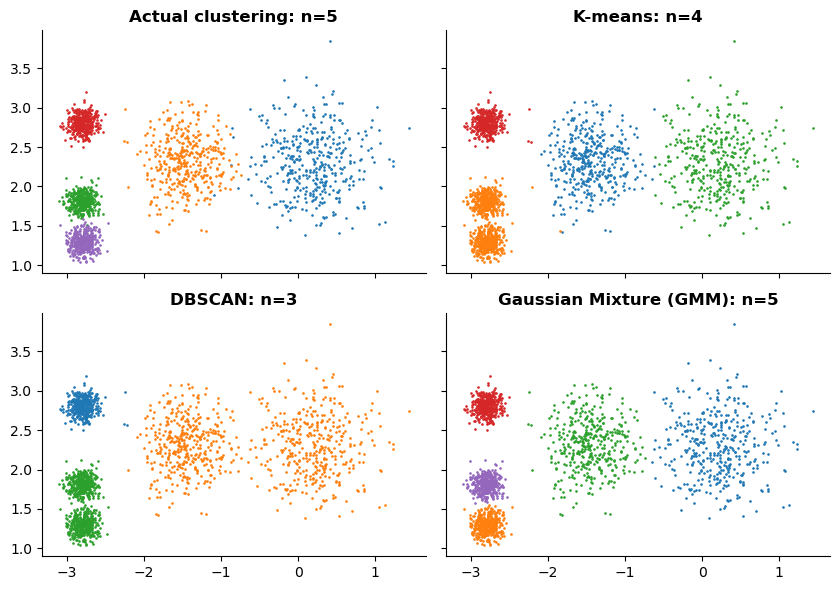

In [6]:
specs = [
    {'n': len(np.unique(y)), 'label': 'Actual clustering', 'predict': lambda _, X_: y},
    {'fit': fit_kmeans, 'n': 4, 'label': 'K-means'},
    {
        'fit': fit_dbscan,
        'label': 'DBSCAN',
        'predict': dbscan_predict,
        'n_stat': dbscan_summary,
    },
    {'fit': fit_gmm, 'n': 5, 'label': 'Gaussian Mixture (GMM)'},
]

show_clusters(specs, X, size=[8.5, 3])

### Fifty Labels, Propagated

Use clustering to make a tiny labeling budget go far: label one representative digit per cluster, propagate the labels to the cluster interiors, and train a classifier that rivals one trained on many more labels.

In [7]:
# ---- 4. Fifty labels, propagated ----
Xtr, Xte, ytr, yte = digits_data()
kmeans, rep_idx = representative_digits(Xtr, k=50)
print(f'\ndigits, 50-label budget:')
print(
    f'  50 random labels             -> test accuracy {baseline_50_random(Xtr, ytr, Xte, yte):.3f}'
)
print(
    f'  50 representative labels     -> test accuracy {train_on_representatives(Xtr, ytr, rep_idx, Xte, yte):.3f}'
)
prop = propagate_and_train(Xtr, ytr, kmeans, rep_idx, Xte, yte, percentile=20)
print(
    f'  propagated to {prop["n_propagated"]} points ({prop["label_accuracy"]:.1%} of them correctly) -> test accuracy {prop["test_accuracy"]:.3f}'
)
print(
    f'  every label ({len(Xtr)})        -> test accuracy {baseline_50_random(Xtr, ytr, Xte, yte, n_labeled=len(Xtr)):.3f}'
)


digits, 50-label budget:
  50 random labels             -> test accuracy 0.804
  50 representative labels     -> test accuracy 0.900
  propagated to 291 points (96.9% of them correctly) -> test accuracy 0.900
  every label (1347)        -> test accuracy 0.962


### Segment an Image, Ship the Model

Use k-means to quantize an image's colors, then save the digit-clustering pipeline and expose a function that assigns raw images to clusters and propagated labels.

In [8]:
# ---- 5. Image segmentation ----
img = synthetic_image(48)
seg = segment_colors(img, k=4)
print(
    f'\ncolor segmentation: {len(np.unique(img.reshape(-1, 3), axis=0))} colors -> {len(np.unique(seg.reshape(-1, 3), axis=0))}'
)


color segmentation: 49 colors -> 4


In [9]:
# ---- 6. Ship the digit clusterer ----
path = os.path.join(tempfile.gettempdir(), 'digit_clusters.pkl')
bundle = save_and_reload_clusterer(kmeans, ytr[rep_idx], path)
digits = load_digits()
preds = predict_digit_labels(bundle, digits.images[:8])
print(f'served on 8 raw images: {preds} (truth {digits.target[:8].tolist()})')

served on 8 raw images: [0, 1, 8, 3, 4, 3, 6, 7] (truth [0, 1, 2, 3, 4, 5, 6, 7])
